<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

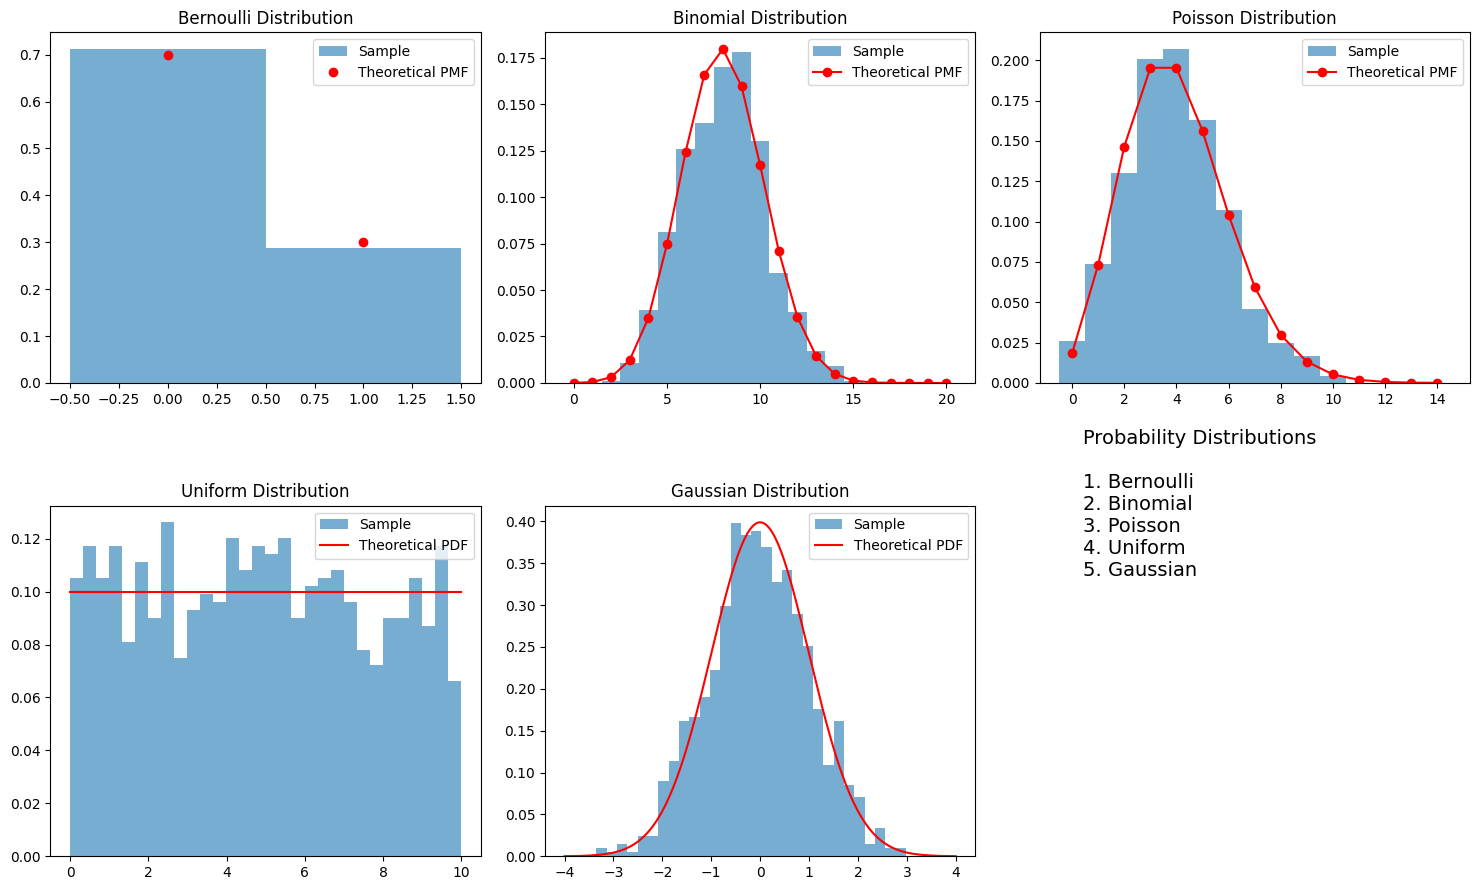


BAYES' THEOREM
----------------------------
Disease Prevalence: 0.01
Sensitivity: 0.95
Specificity: 0.9
False Positive Rate: 0.09999999999999998
P(Disease | Positive) = 0.0876
Posterior Probability = 8.76 %

SIMULATION RESULTS
----------------------------
Total Patients: 100000
True Positive: 925
False Positive: 9912
Total Positive: 10837
Empirical Probability = 8.54 %
Theoretical Probability = 8.76 %


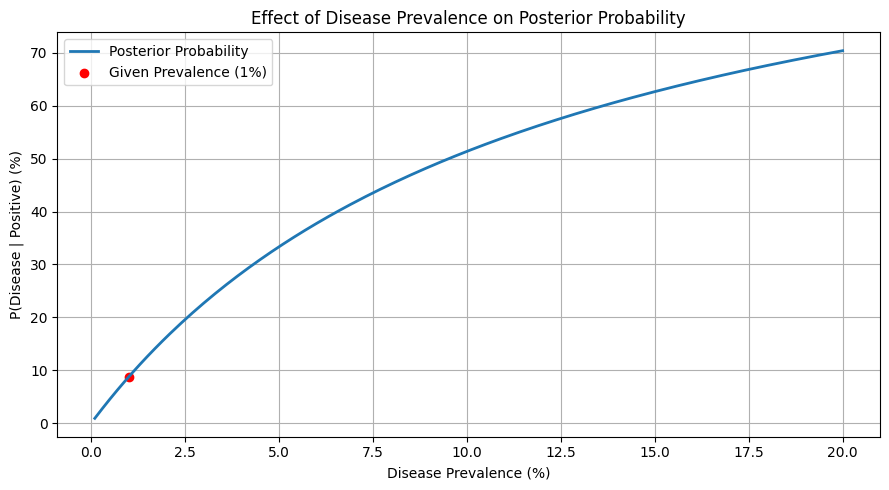

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import bernoulli, binom, poisson, uniform, norm

# Reproducible random values
np.random.seed(42)

# -----------------------------------------
# TASK 1: PROBABILITY DISTRIBUTIONS
# -----------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

# 1. Bernoulli Distribution
p = 0.3
data = bernoulli.rvs(p, size=1000)

x = [0, 1]
axes[0, 0].hist(data, bins=[-0.5, 0.5, 1.5],
                density=True, alpha=0.6, label="Sample")

axes[0, 0].plot(x, bernoulli.pmf(x, p), 'ro',
                label="Theoretical PMF")

axes[0, 0].set_title("Bernoulli Distribution")
axes[0, 0].legend()

# 2. Binomial Distribution
n, p = 20, 0.4
data = binom.rvs(n, p, size=1000)

x = np.arange(0, n + 1)

axes[0, 1].hist(data, bins=np.arange(-0.5, n + 1.5),
                density=True, alpha=0.6, label="Sample")

axes[0, 1].plot(x, binom.pmf(x, n, p), 'ro-',
                label="Theoretical PMF")

axes[0, 1].set_title("Binomial Distribution")
axes[0, 1].legend()

# 3. Poisson Distribution
mu = 4
data = poisson.rvs(mu, size=1000)

x = np.arange(0, 15)

axes[0, 2].hist(data, bins=np.arange(-0.5, 15.5),
                density=True, alpha=0.6, label="Sample")

axes[0, 2].plot(x, poisson.pmf(x, mu), 'ro-',
                label="Theoretical PMF")

axes[0, 2].set_title("Poisson Distribution")
axes[0, 2].legend()

# 4. Uniform Distribution
low, high = 0, 10
data = uniform.rvs(loc=low, scale=high-low, size=1000)

x = np.linspace(0, 10, 200)

axes[1, 0].hist(data, bins=30, density=True,
                alpha=0.6, label="Sample")

axes[1, 0].plot(x, uniform.pdf(x, loc=low,
                scale=high-low), 'r',
                label="Theoretical PDF")

axes[1, 0].set_title("Uniform Distribution")
axes[1, 0].legend()

# 5. Gaussian Distribution
mean, std = 0, 1
data = norm.rvs(loc=mean, scale=std, size=1000)

x = np.linspace(-4, 4, 200)

axes[1, 1].hist(data, bins=30, density=True,
                alpha=0.6, label="Sample")

axes[1, 1].plot(x, norm.pdf(x, mean, std), 'r',
                label="Theoretical PDF")

axes[1, 1].set_title("Gaussian Distribution")
axes[1, 1].legend()

# 6. Display all distributions
axes[1, 2].axis("off")
axes[1, 2].text(0.1, 0.8,
                "Probability Distributions\n\n"
                "1. Bernoulli\n"
                "2. Binomial\n"
                "3. Poisson\n"
                "4. Uniform\n"
                "5. Gaussian",
                fontsize=14)

plt.tight_layout()
plt.show()


# -----------------------------------------
# TASK 2: BAYES' THEOREM
# -----------------------------------------

prevalence = 0.01
sensitivity = 0.95
specificity = 0.90

false_positive_rate = 1 - specificity

numerator = sensitivity * prevalence

denominator = (
    numerator +
    false_positive_rate * (1 - prevalence)
)

posterior = numerator / denominator

print("\nBAYES' THEOREM")
print("----------------------------")
print("Disease Prevalence:", prevalence)
print("Sensitivity:", sensitivity)
print("Specificity:", specificity)
print("False Positive Rate:", false_positive_rate)

print("P(Disease | Positive) =",
      round(posterior, 4))

print("Posterior Probability =",
      round(posterior * 100, 2), "%")


# -----------------------------------------
# TASK 3: SIMULATION OF 100,000 PATIENTS
# -----------------------------------------

N = 100000

# Generate disease status
disease = np.random.binomial(1, prevalence, N)

# Generate test results
test_positive = np.zeros(N, dtype=int)

for i in range(N):

    if disease[i] == 1:
        test_positive[i] = np.random.binomial(
            1, sensitivity
        )
    else:
        test_positive[i] = np.random.binomial(
            1, false_positive_rate
        )

# Calculate actual cases
true_positive = np.sum(
    (disease == 1) & (test_positive == 1)
)

false_positive = np.sum(
    (disease == 0) & (test_positive == 1)
)

positive_cases = np.sum(test_positive)

empirical_probability = (
    true_positive / positive_cases
)

print("\nSIMULATION RESULTS")
print("----------------------------")
print("Total Patients:", N)
print("True Positive:", true_positive)
print("False Positive:", false_positive)
print("Total Positive:", positive_cases)

print("Empirical Probability =",
      round(empirical_probability * 100, 2), "%")

print("Theoretical Probability =",
      round(posterior * 100, 2), "%")


# -----------------------------------------
# TASK 4: PREVALENCE VS POSTERIOR
# -----------------------------------------

prevalences = np.linspace(0.001, 0.20, 200)

posteriors = (
    sensitivity * prevalences
) / (
    sensitivity * prevalences +
    false_positive_rate * (1 - prevalences)
)

plt.figure(figsize=(9, 5))

plt.plot(prevalences * 100,
         posteriors * 100,
         linewidth=2,
         label="Posterior Probability")

plt.scatter(1, posterior * 100,
            color="red",
            label="Given Prevalence (1%)")

plt.xlabel("Disease Prevalence (%)")
plt.ylabel("P(Disease | Positive) (%)")

plt.title("Effect of Disease Prevalence on Posterior Probability")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
